Dataset shape: (569, 30) | Labels: 0=Malignant, 1=Benign


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Missing values: 0
Duplicate rows: 0
Training rows: 455 | Test rows: 114


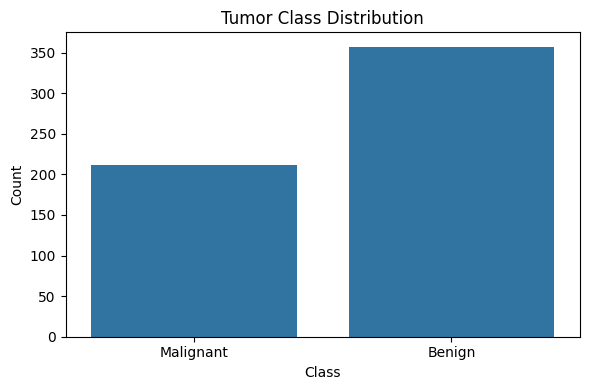

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.8159 - loss: 0.5260 - val_accuracy: 0.9231 - val_loss: 0.4382
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.9121 - loss: 0.3373 - val_accuracy: 0.9451 - val_loss: 0.2882
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9533 - loss: 0.2304 - val_accuracy: 0.9451 - val_loss: 0.2052
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9533 - loss: 0.1767 - val_accuracy: 0.9560 - val_loss: 0.1589
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9615 - loss: 0.1424 - val_accuracy: 0.9670 - val_loss: 0.1304
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9698 - loss: 0.1118 - val_accuracy: 0.9670 - val_loss: 0.1114
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9753 - loss: 0.0983 - val_accuracy: 0.9670 - val_loss: 0.0976
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9808 - loss: 0.0972 - val_accuracy: 0.9

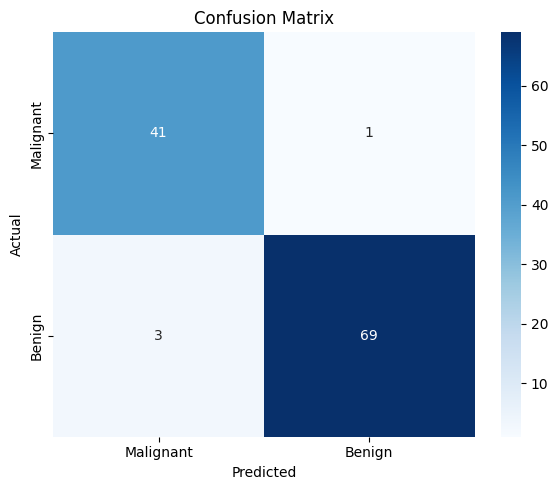

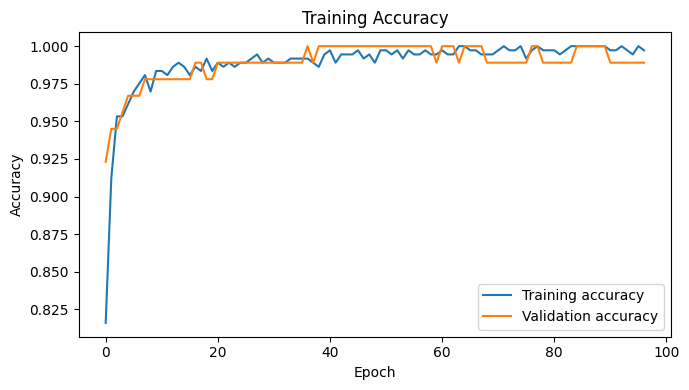

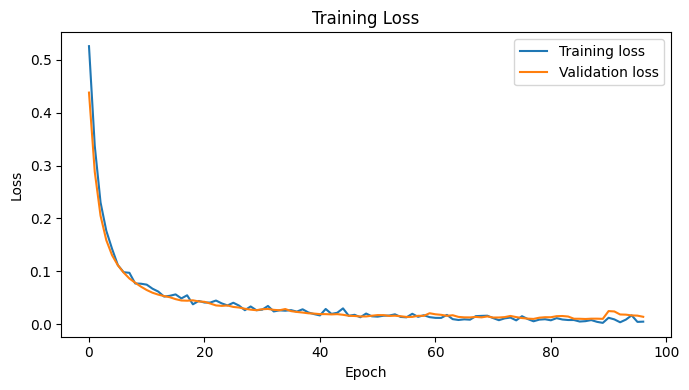

\nSAMPLE PREDICTION
Predicted: Malignant | Actual dataset label: Malignant
Model output for Benign class: 0.0
\nSaved model, metrics, prediction and graphs in: /content/cancer_project_outputs
Educational project only — not for medical diagnosis.


In [1]:
%pip -q install tensorflow scikit-learn seaborn joblib
# Cancer Classification and Prediction Using Neural Networks
# Educational demonstration only — NOT for medical diagnosis.
import os, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import joblib
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
OUT = Path("cancer_project_outputs")
OUT.mkdir(exist_ok=True)

# 1. Load data (no CSV upload required)
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")  # 0 = malignant, 1 = benign
print("Dataset shape:", X.shape, "| Labels: 0=Malignant, 1=Benign")
display(X.head())

# 2. Inspect and clean
print("Missing values:", int(X.isna().sum().sum()))
combined = X.copy()
combined["target"] = y
print("Duplicate rows:", int(combined.duplicated().sum()))
combined = combined.drop_duplicates()
X = combined.drop(columns=["target"]).reset_index(drop=True)
y = combined["target"].astype(int).reset_index(drop=True)

# 3. Split before preprocessing to avoid test leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Training rows:", len(y_train), "| Test rows:", len(y_test))

# 4. Visualize class balance
plt.figure(figsize=(6,4))
sns.countplot(x=y.map({0:"Malignant", 1:"Benign"}))
plt.title("Tumor Class Distribution"); plt.xlabel("Class"); plt.ylabel("Count")
plt.tight_layout(); plt.savefig(OUT/"class_distribution.png", dpi=160); plt.show()

# 5. Build neural network
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32, activation="relu"),
    Dropout(0.20),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

# 6. Train
stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
history = model.fit(
    X_train, y_train, validation_split=0.20, epochs=100,
    batch_size=16, callbacks=[stop], verbose=1
)

# 7. Evaluate on held-out test data
prob = model.predict(X_test, verbose=0).ravel()
pred = (prob >= 0.5).astype(int)
metrics = {
    "accuracy": float(accuracy_score(y_test, pred)),
    "precision": float(precision_score(y_test, pred, zero_division=0)),
    "recall": float(recall_score(y_test, pred, zero_division=0)),
    "f1_score": float(f1_score(y_test, pred, zero_division=0)),
    "training_samples": int(len(y_train)),
    "test_samples": int(len(y_test)),
    "features": int(X.shape[1]),
    "label_mapping": {"0": "Malignant", "1": "Benign"}
}
print("\\nTEST METRICS")
for k in ["accuracy", "precision", "recall", "f1_score"]:
    print(f"{k}: {metrics[k]:.4f}" + (f" ({metrics[k]*100:.2f}%)" if k=="accuracy" else ""))
print(classification_report(y_test, pred, labels=[0,1], target_names=["Malignant","Benign"], zero_division=0))
(OUT/"metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
(OUT/"classification_report.txt").write_text(classification_report(y_test, pred, labels=[0,1], target_names=["Malignant","Benign"], zero_division=0), encoding="utf-8")

# 8. Confusion matrix
cm = confusion_matrix(y_test, pred, labels=[0,1])
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Malignant","Benign"], yticklabels=["Malignant","Benign"])
plt.title("Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.savefig(OUT/"confusion_matrix.png", dpi=160); plt.show()

# 9. Training curves
plt.figure(figsize=(7,4))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Training Accuracy")
plt.legend(); plt.tight_layout(); plt.savefig(OUT/"training_accuracy.png", dpi=160); plt.show()

plt.figure(figsize=(7,4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Training Loss")
plt.legend(); plt.tight_layout(); plt.savefig(OUT/"training_loss.png", dpi=160); plt.show()

# 10. Example prediction on a held-out test record
names = {0:"Malignant", 1:"Benign"}
i = 0
print("\\nSAMPLE PREDICTION")
print("Predicted:", names[int(pred[i])], "| Actual dataset label:", names[int(y_test.iloc[i])])
print("Model output for Benign class:", round(float(prob[i]), 4))

# 11. Save model and preprocessing
model.save(OUT/"cancer_classification_model.keras")
joblib.dump(imputer, OUT/"imputer.joblib")
joblib.dump(scaler, OUT/"scaler.joblib")
pd.DataFrame([metrics]).to_csv(OUT/"evaluation_results.csv", index=False)
pd.DataFrame([{"predicted_class":names[int(pred[i])],
               "actual_label":names[int(y_test.iloc[i])],
               "benign_score":float(prob[i])}]).to_csv(OUT/"sample_prediction.csv", index=False)
print("\\nSaved model, metrics, prediction and graphs in:", OUT.resolve())
print("Educational project only — not for medical diagnosis.")
